# EDA 03 · Transactions table

**Part I · Raw tables** · part of the 10-notebook EDA series in `workshops/w1/eda/` (index in `README.md`).

**Question.** How do plans, prices and payment methods behave, and where do list price and amount paid differ?

**Data.** Raw files converted to parquet in `workshops/data/parquet/`. The target is the labelled March cohort `train_v2` (970,960 users, 9.0 % churn).

**How to read it.** Follow the sequence: payment method, plan days, list price, amount paid, then the price difference.

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

# Paths resolve from the w1 folder, whether the notebook runs from workshops/w1 or workshops/w1/eda.
W1_DIR = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
DATA_DIR = W1_DIR.parent / "data"      # workshops/data: raw .csv.7z archives
PARQUET_DIR = DATA_DIR / "parquet"     # created once by notebook 01 (or by w1_data_preprocessing)

sns.set()
warnings.filterwarnings("ignore")

PCTS = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 98, 99, 99.5, 99.99, 99.999, 100]


def tabla_percentiles(serie):
    return pd.DataFrame(np.percentile(serie, PCTS), index=PCTS, columns=["valor"])

## 3. Transactions

**Note:** transaction data comes in two parts; only the second part is used for visualisation.

In [32]:
# transactions_v2.parquet; both transaction files are used in preprocessing
transaction_data = pl.read_parquet(PARQUET_DIR / "transactions_v2.parquet").to_pandas()
for col in ("transaction_date", "membership_expire_date"):
    transaction_data[col] = pd.to_datetime(
        transaction_data[col].astype(str), format="%Y%m%d")

In [33]:
transaction_data.head()

,msno,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
0,++6eU4LsQ3UQ20ILS7d99XK8WbiVgbyYL4FUgzZR134=,32,90,298,298,0,2017-01-31,2017-05-04,0
1,++lvGPJOinuin/8esghpnqdljm6NXS8m8Zwchc7gOeA=,41,30,149,149,1,2015-08-09,2019-04-12,0
2,+/GXNtXWQVfKrEDqYAzcSw2xSPYMKWNj22m+5XkVQZc=,36,30,180,180,1,2017-03-03,2017-04-22,0
3,+/w1UrZwyka4C9oNH3+Q8fUf3fD8R3EwWrx57ODIsqk=,36,30,180,180,1,2017-03-29,2017-03-31,1
4,+00PGzKTYqtnb65mPKPyeHXcZEwqiEzktpQksaaSC3c=,41,30,99,99,1,2017-03-23,2017-04-23,0


This dataframe has 9 features. There are no string features except the id (`msno`).

In [34]:
transaction_data.describe().apply(lambda s: s.apply(lambda x: format(x, "f")))

,payment_method_id,payment_plan_days,plan_list_price,actual_amount_paid,is_auto_renew,transaction_date,membership_expire_date,is_cancel
count,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000,1431009.000000
mean,37.918355,66.017696,281.787035,281.317241,0.785303,f,f,0.024551
min,2.000000,0.000000,0.000000,0.000000,0.000000,f,f,0.000000
25%,36.000000,30.000000,99.000000,99.000000,1.000000,f,f,0.000000
50%,40.000000,30.000000,149.000000,149.000000,1.000000,f,f,0.000000
75%,41.000000,30.000000,149.000000,149.000000,1.000000,f,f,0.000000
max,41.000000,450.000000,2000.000000,2000.000000,1.000000,f,f,1.000000
std,4.964805,102.486396,435.186138,435.419950,0.410612,nan,nan,0.154753


No outliers in `is_auto_renew` or `is_cancel`. The high-level statistics of `actual_amount_paid` and `plan_list_price` are similar, but their means differ, so there is some difference between them.

In [35]:
transaction_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1431009 entries, 0 to 1431008
Data columns (total 9 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   msno                    1431009 non-null  str           
 1   payment_method_id       1431009 non-null  int8          
 2   payment_plan_days       1431009 non-null  int16         
 3   plan_list_price         1431009 non-null  int16         
 4   actual_amount_paid      1431009 non-null  int16         
 5   is_auto_renew           1431009 non-null  int8          
 6   transaction_date        1431009 non-null  datetime64[us]
 7   membership_expire_date  1431009 non-null  datetime64[us]
 8   is_cancel               1431009 non-null  int8          
dtypes: datetime64[us](2), int16(3), int8(3), str(1)
memory usage: 105.1 MB


The same memory optimization can be used.

In [36]:
transaction_data.shape

(1431009, 9)

### Plotting count vs payment_method_id

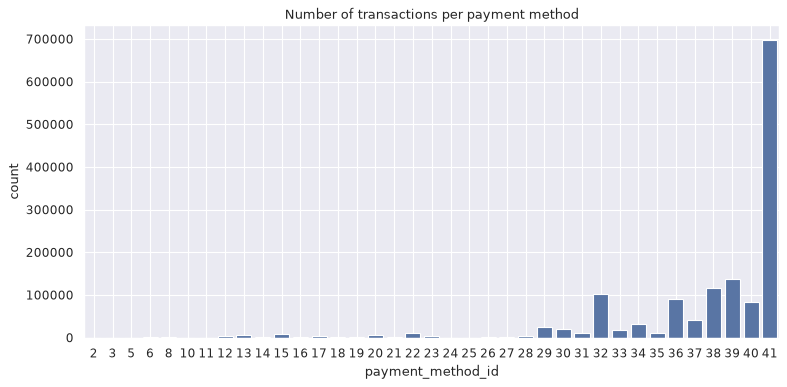

In [37]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=transaction_data["payment_method_id"])
plt.title("Number of transactions per payment method")
plt.xlabel("payment_method_id")
plt.ylabel("count")
plt.tight_layout()
plt.grid(True)
plt.show()

In [38]:
tabla_percentiles(transaction_data["payment_method_id"])

,valor
0.000,2.0
10.000,32.0
20.000,36.0
30.000,38.0
40.000,39.0
50.000,40.0
60.000,41.0
70.000,41.0
80.000,41.0
90.000,41.0


The later payment methods are more popular; method 41 is the most used. Since it is an int, it has to be encoded. There are large category values, so one-hot encoding would create sparsity. As feature engineering we can flag whether the user uses a more popular method.

### Plotting count vs payment_plan_days

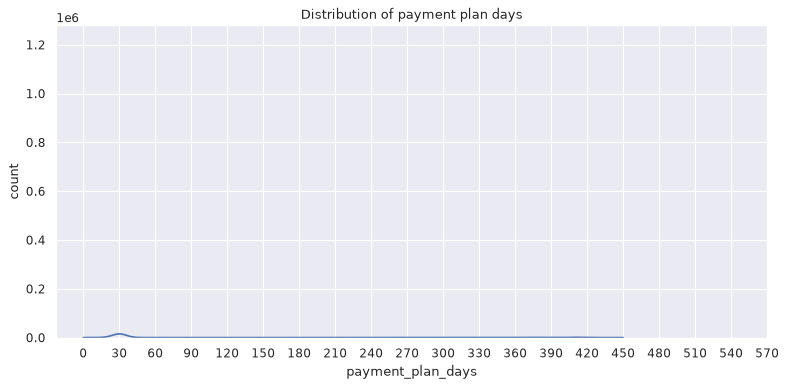

In [39]:
figure(num=None, figsize=(10, 5), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["payment_plan_days"], kde=True)
plt.title("Distribution of payment plan days")
plt.xlabel("payment_plan_days")
plt.ylabel("count")
plt.xticks(range(0, 600, 30))
plt.tight_layout()
plt.show()

In [40]:
tabla_percentiles(transaction_data["payment_plan_days"])

,valor
0.000,0.0
10.000,30.0
20.000,30.0
30.000,30.0
40.000,30.0
50.000,30.0
60.000,30.0
70.000,30.0
80.000,30.0
90.000,195.0


Almost everyone takes a 30-day plan. People who take a 420-day plan are less likely to churn. We can build an indicator of whether the plan is above 150 days.

### Plotting count vs plan_list_price

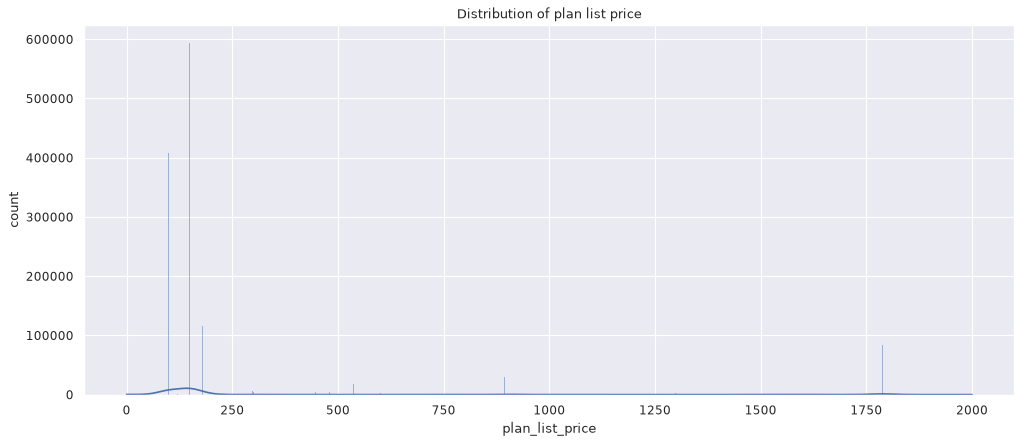

In [41]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["plan_list_price"], kde=True)
plt.title("Distribution of plan list price")
plt.xlabel("plan_list_price")
plt.ylabel("count")
plt.show()

In [42]:
tabla_percentiles(transaction_data["plan_list_price"])

,valor
0.000,0.0
10.000,99.0
20.000,99.0
30.000,100.0
40.000,149.0
50.000,149.0
60.000,149.0
70.000,149.0
80.000,180.0
90.000,799.0


Some people choose a very high price. These passionate users tend not to churn, so an indicator can be used.

### Plotting count vs actual amount paid

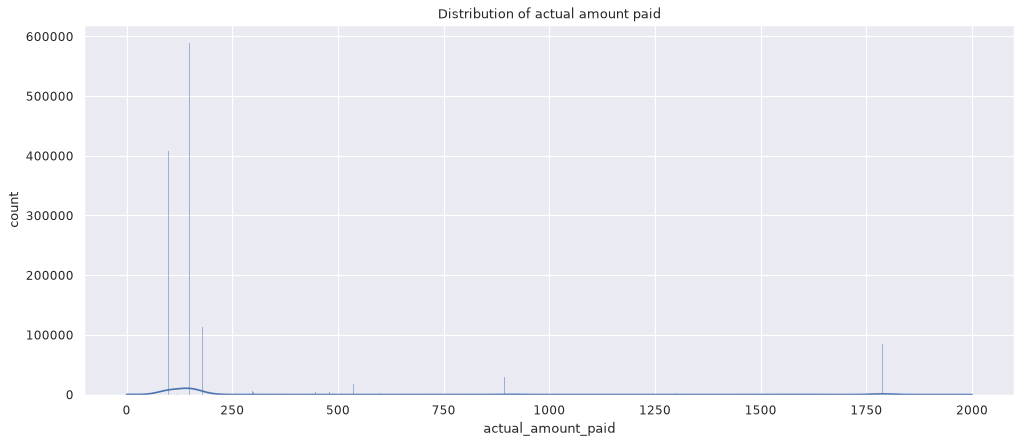

In [43]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.histplot(x=transaction_data["actual_amount_paid"], kde=True)
plt.title("Distribution of actual amount paid")
plt.xlabel("actual_amount_paid")
plt.ylabel("count")
plt.show()

In [44]:
tabla_percentiles(transaction_data["actual_amount_paid"])

,valor
0.000,0.0
10.000,99.0
20.000,99.0
30.000,99.0
40.000,149.0
50.000,149.0
60.000,149.0
70.000,149.0
80.000,180.0
90.000,799.0


The actual amount paid and plan list price graphs are almost identical. No obvious distinction can be made; a deeper study is required.

### Plots between

1. counts and `is_auto_renew`
2. counts and `is_cancel`

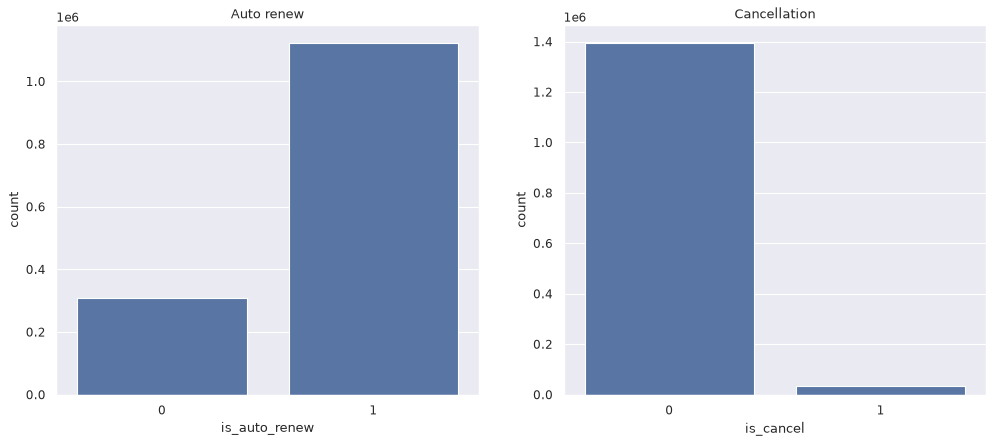

In [45]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
plt.subplot(121)
sns.countplot(x=transaction_data["is_auto_renew"])
plt.title("Auto renew")
plt.xlabel("is_auto_renew")
plt.ylabel("count")
plt.subplot(122)
sns.countplot(x=transaction_data["is_cancel"])
plt.title("Cancellation")
plt.xlabel("is_cancel")
plt.ylabel("count")
plt.show()

**Transactions.**

- `payment_method_id`: 41 is the most used. Because there are many categories, a flag is better than one-hot.
- `payment_plan_days`: almost all plans are 30 days and there are long plans (up to ~450). A long plan indicates a committed user.
- `plan_list_price` and `actual_amount_paid` are distributed almost identically. In the rows where they differ, the difference concentrates on 30, 149 and 180, and some users pay more than the list price. That difference is a feature.
- `is_auto_renew` is active in most cases and `is_cancel` is infrequent.

There are two date features, `transaction_date` and `membership_expire_date`, used to decide whether the user churned: if there is no new subscription within 30 days, the customer is considered churned.

Since theoretical and actual price look almost the same at first, let's go deeper to check whether there is a difference.

In [46]:
(transaction_data["actual_amount_paid"] != transaction_data["plan_list_price"]).value_counts()

False    1419106
True       11903
Name: count, dtype: int64

There is some difference between the actual and theoretical price paid by users.

In [47]:
temp_data = transaction_data[transaction_data["actual_amount_paid"] != transaction_data["plan_list_price"]]
# checking only where there is actually a difference

### Plot count vs difference in the actual and paid amount

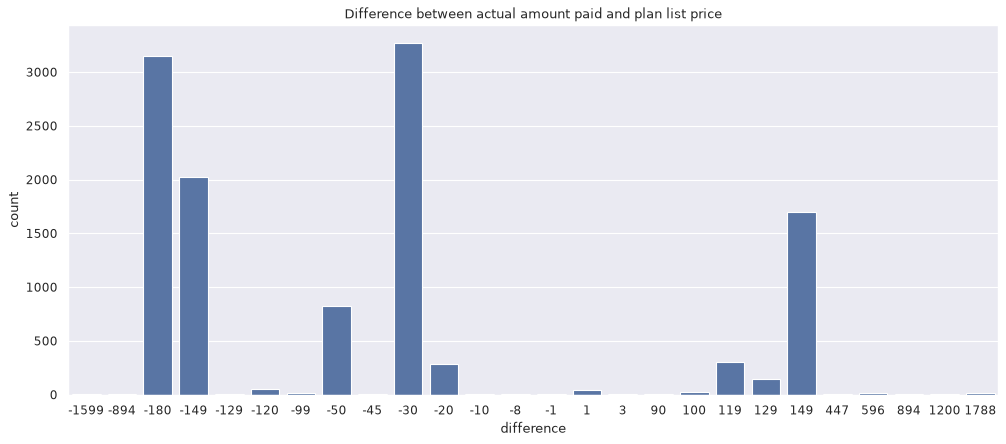

In [48]:
figure(num=None, figsize=(15, 6), dpi=80, facecolor="w", edgecolor="k")
sns.countplot(x=temp_data["actual_amount_paid"] - temp_data["plan_list_price"])
plt.title("Difference between actual amount paid and plan list price")
plt.xlabel("difference")
plt.ylabel("count")
plt.show()

Most people got a difference of 30, 149 and 180. The most interesting thing is that people are paying more than they should have.

---
**Previous:** `02_members.ipynb` · **Next:** `04_user_logs.ipynb`